In [ ]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df = pd.read_csv('../data/daily_bike_weather.csv', parse_dates=['대여일자'])

holidays = pd.to_datetime([
    '2026-01-01', '2026-02-16', '2026-02-17', '2026-02-18',
    '2026-03-02', '2026-05-01', '2026-05-05', '2026-05-25', '2026-06-03'
])

# 회귀용 데이터: 영문 컬럼명으로 정리
m = pd.DataFrame({
    'log_y':   np.log(df['이용건수']),
    'temp':    df['평균기온'],
    'rain':    pd.cut(df['강수량_mm'], bins=[-0.1, 0, 5, 20, 1000],
                      labels=['a_0mm', 'b_0to5', 'c_5to20', 'd_20plus']),
    'holiday': (df['대여일자'].isin(holidays) | df['요일'].isin(['Saturday', 'Sunday'])).astype(int),
    'wind':    df['평균풍속'],
    'month':   df['대여일자'].dt.month,
})

base = 'log_y ~ temp + I(temp**2) + C(rain) + holiday + wind'
A = smf.ols(base, data=m).fit()                   # 모델 A: 월 없음
B = smf.ols(base + ' + C(month)', data=m).fit()   # 모델 B: 월 고정효과 추가

print(f"R²  모델 A: {A.rsquared:.3f}   모델 B: {B.rsquared:.3f}")

terms = ['C(rain)[T.b_0to5]', 'C(rain)[T.c_5to20]', 'C(rain)[T.d_20plus]', 'holiday', 'wind']
names = ['비 0~5mm', '비 5~20mm', '비 20mm+', '휴일', '풍속 1m/s']
out = pd.DataFrame({
    'A 효과(%)': ((np.exp(A.params[terms]) - 1) * 100).round(1).values,
    'A p값':     A.pvalues[terms].round(3).values,
    'B 효과(%)': ((np.exp(B.params[terms]) - 1) * 100).round(1).values,
    'B p값':     B.pvalues[terms].round(3).values,
}, index=names)

holidays = pd.to_datetime([
    '2026-01-01', '2026-02-16', '2026-02-17', '2026-02-18',
    '2026-03-02', '2026-05-01', '2026-05-05', '2026-05-25', '2026-06-03'
])

# 회귀용 데이터: 영문 컬럼명으로 정리
m = pd.DataFrame({
    'log_y':   np.log(df['이용건수']),
    'temp':    df['평균기온'],
    'rain':    pd.cut(df['강수량_mm'], bins=[-0.1, 0, 5, 20, 1000],
                      labels=['a_0mm', 'b_0to5', 'c_5to20', 'd_20plus']),
    'holiday': (df['대여일자'].isin(holidays) | df['요일'].isin(['Saturday', 'Sunday'])).astype(int),
    'wind':    df['평균풍속'],
    'month':   df['대여일자'].dt.month,
})

base = 'log_y ~ temp + I(temp**2) + C(rain) + holiday + wind'
A = smf.ols(base, data=m).fit()                   # 모델 A: 월 없음
B = smf.ols(base + ' + C(month)', data=m).fit()   # 모델 B: 월 고정효과 추가

print(f"R²  모델 A: {A.rsquared:.3f}   모델 B: {B.rsquared:.3f}")

terms = ['C(rain)[T.b_0to5]', 'C(rain)[T.c_5to20]', 'C(rain)[T.d_20plus]', 'holiday', 'wind']
names = ['비 0~5mm', '비 5~20mm', '비 20mm+', '휴일', '풍속 1m/s']
out = pd.DataFrame({
    'A 효과(%)': ((np.exp(A.params[terms]) - 1) * 100).round(1).values,
    'A p값':     A.pvalues[terms].round(3).values,
    'B 효과(%)': ((np.exp(B.params[terms]) - 1) * 100).round(1).values,
    'B p값':     B.pvalues[terms].round(3).values,
}, index=names)

out

R²  모델 A: 0.845   모델 B: 0.873
R²  모델 A: 0.845   모델 B: 0.873


,A 효과(%),A p값,B 효과(%),B p값
비 0~5mm,-19.9,0.000,-22.8,0.000
비 5~20mm,-48.6,0.000,-51.2,0.000
비 20mm+,-83.3,0.000,-83.7,0.000
휴일,-26.9,0.000,-26.2,0.000
풍속 1m/s,-4.7,0.106,-8.0,0.003


모델 A 비 20mm+ 95% 신뢰구간: -88% ~ -77%
모델 B 비 20mm+ 95% 신뢰구간: -88% ~ -78%


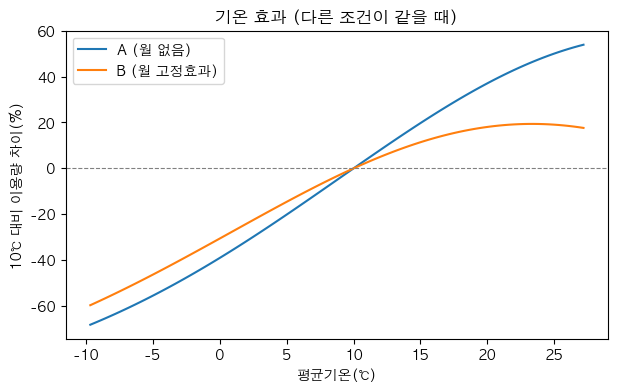

모델 A 최적 기온: 32.6℃
모델 B 최적 기온: 23.3℃


In [4]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

# 1) 20mm+ 효과의 95% 신뢰구간 (표본 2일이라 범위가 얼마나 넓은지 확인)
for name, model in [('A', A), ('B', B)]:
    lo, hi = np.exp(model.conf_int().loc['C(rain)[T.d_20plus]']) - 1
    print(f"모델 {name} 비 20mm+ 95% 신뢰구간: {lo*100:.0f}% ~ {hi*100:.0f}%")

# 2) 기온 효과 곡선: 10℃를 기준(0%)으로 다른 기온에서 이용량이 몇 % 다른지
t = np.linspace(m['temp'].min(), m['temp'].max(), 100)
plt.figure(figsize=(7, 4))
for name, model in [('A (월 없음)', A), ('B (월 고정효과)', B)]:
    b1, b2 = model.params['temp'], model.params['I(temp ** 2)']
    effect = np.exp(b1 * (t - 10) + b2 * (t**2 - 100)) - 1
    plt.plot(t, effect * 100, label=name)
plt.axhline(0, color='gray', lw=0.8, ls='--')
plt.xlabel('평균기온(℃)')
plt.ylabel('10℃ 대비 이용량 차이(%)')
plt.title('기온 효과 (다른 조건이 같을 때)')
plt.legend()
plt.savefig('../images/temp_effect.png', dpi=150, bbox_inches='tight')
plt.show()

# 3) 이용량이 최대가 되는 기온
for name, model in [('A', A), ('B', B)]:
    b1, b2 = model.params['temp'], model.params['I(temp ** 2)']
    print(f"모델 {name} 최적 기온: {-b1 / (2 * b2):.1f}℃" if b2 < 0 else f"모델 {name}: 아직 꺾이지 않음")

In [5]:
monthly = df.groupby(df['대여일자'].dt.month).agg(
    평균풍속=('평균풍속', 'mean'),
    일평균이용=('이용건수', 'mean'),
).round(1)
monthly

,평균풍속,일평균이용
대여일자,,
1,2.5,51476.9
2,2.3,62309.1
3,2.4,91682.8
4,2.4,127471.9
5,2.3,125969.1
6,2.1,135551.3
